<a href="https://colab.research.google.com/github/9abinash/Heroku-Demo/blob/master/langgraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install langgraph langchain langchain-openai pydantic python-dotenv gradio ipython tiktoken langsmith

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.8/119.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 39.7 MB/s eta 0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.4.3
    Uninstalling langchain-core-1.4.3:
      Successfully uninstalled langchain-core-1.4.3


In [ ]:
from langgraph.graph import START, StateGraph, END
from langgraph.graph.message import add_messages
from typing import Annotated
from dotenv import load_dotenv
from pydantic import BaseModel
import random
import gradio as gr
from IPython.display import Image, display
from langchain_openai import ChatOpenAI

In [ ]:
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Zombies", "Rainbows", "Eels", "Pickles", "Muffins"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "moody", "sparkly", "untrustworthy", "sarcastic", "squishy", "haunted"]

In [ ]:
load_dotenv(override=True)

False

In [ ]:
def shout(text: Annotated[str, "something to be shouted"]) -> str:
    print(text.upper())
    return text.upper()

shout("hello")

HELLO


'HELLO'

**Step 1: Define the State object**

In [ ]:
from langchain_core.messages import BaseMessage

class State(BaseModel):
  messages: Annotated[list[BaseMessage], add_messages]

**Step 2:Start the groh builder**



In [ ]:
graph_builder = StateGraph(State)

bold text

In [ ]:
llm = ChatOpenAI(model="gpt-4o-mini")

def chatbot_node(state: State) -> State:
    response = llm.invoke(state.messages)
    return State(messages=[response])

graph_builder.add_node("chatbot", chatbot_node)

In [ ]:
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

In [ ]:
graph = graph_builder.compile()

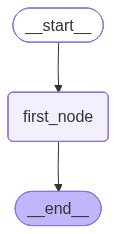

In [ ]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
def chat(user_input: str, history):
    message = {"role": "user", "content": user_input}
    messages = [message]
    state = State(messages=messages)
    result = graph.invoke(state)
    print(result)
    return result["messages"][-1].content


gr.ChatInterface(chat, type="messages").launch(share=True,debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://81ceedfa390c80058d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/langchain_core/messages/utils.py", line 713, in _convert_to_message
    msg_type = msg_kwargs.pop("role")
               ^^^^^^^^^^^^^^^^^^^^^^
KeyError: 'role'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/langchain_core/messages/utils.py", line 715, in _convert_to_message
    msg_type = msg_kwargs.pop("type")
               ^^^^^^^^^^^^^^^^^^^^^^
KeyError: 'type'

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/gradio/queueing.py", line 759, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/gradio/route_utils.py", line 354, in call_process_api
    output = await app.get_blocks()